<a href="https://colab.research.google.com/github/Destian0870/PCVK_Ganjil2026/blob/main/Destian_JB7_PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TUGAS PRAKTIKUM**

D1. Tugas Individu

1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

2. Import Library

In [2]:
# Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. Global Thresholding Manual ($T = 200$)

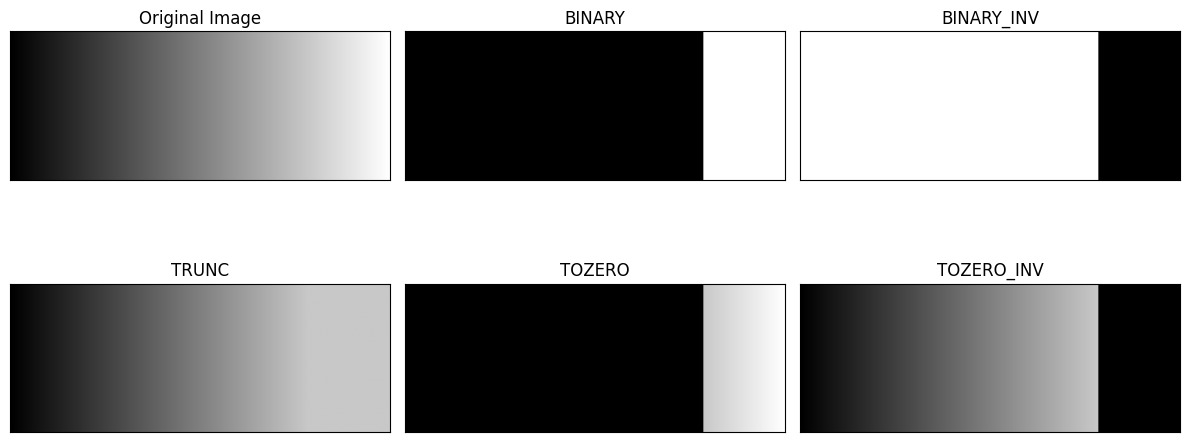

In [3]:
gradient = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (100, 1))

thresh = 200
max_val = 255

binary = np.where(gradient > thresh, max_val, 0).astype(np.uint8)
binary_inv = np.where(gradient > thresh, 0, max_val).astype(np.uint8)
trunc = np.where(gradient > thresh, thresh, gradient).astype(np.uint8)
tozero = np.where(gradient > thresh, gradient, 0).astype(np.uint8)
tozero_inv = np.where(gradient > thresh, 0, gradient).astype(np.uint8)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [gradient, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(12, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

4. Adaptive Thresholding Manual (Sudoku Image)

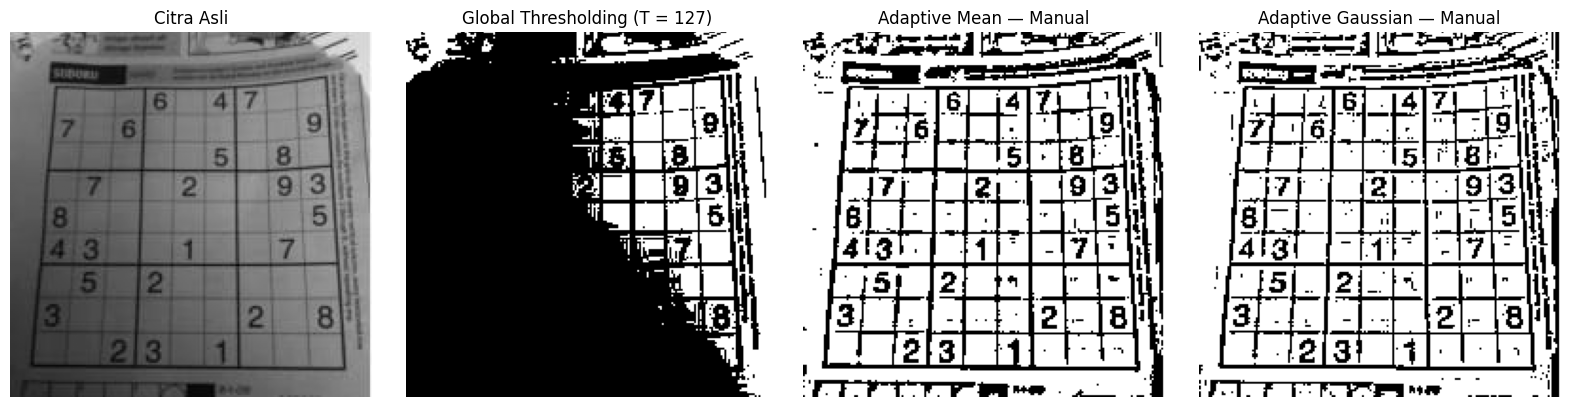

In [5]:
# Load citra Sudoku (pastikan file 'sudoku.jpg' / 'dave.jpg' sudah diunggah/ada di path Drive)
img_sudoku = cv.imread('/content/drive/MyDrive/PCVK/Images/sudoku.jpg', 0)
if img_sudoku is None: # Fallback jika lokasi file lokal
    img_sudoku = cv.imread('sudoku.jpeg', 0)

# Global Thresholding Manual (T = 127)
global_thresh = np.where(img_sudoku > 127, 255, 0).astype(np.uint8)

# Fungsi Adaptive Thresholding Manual
def adaptive_threshold_manual(img, window_size=11, C=2, method='mean', sigma=2):
    pad = window_size // 2
    padded_img = np.pad(img, pad, mode='reflect').astype(np.float32)
    h, w = img.shape
    threshold_map = np.zeros((h, w), dtype=np.float32)

    if method == 'gaussian':
        # Buat Kernel Gaussian 2D
        k = cv.getGaussianKernel(window_size, sigma)
        kernel = k @ k.T

    for i in range(h):
        for j in range(w):
            region = padded_img[i:i+window_size, j:j+window_size]
            if method == 'mean':
                local_mean = np.mean(region)
            elif method == 'gaussian':
                local_mean = np.sum(region * kernel)
            threshold_map[i, j] = local_mean - C

    # Binarisasi: Jika piksel > T - C maka 255, selain itu 0
    binary_out = np.where(img > threshold_map, 255, 0).astype(np.uint8)
    return binary_out

# Jalankan Adaptive Thresholding Manual
adaptive_mean = adaptive_threshold_manual(img_sudoku, window_size=11, C=2, method='mean')
adaptive_gaussian = adaptive_threshold_manual(img_sudoku, window_size=11, C=2, method='gaussian', sigma=2)

# Visualisasi
titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
images = [img_sudoku, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(16, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

5. Otsu Thresholding Manual (Lena & KTP)

A. Kode Implementasi

In [10]:
import cv2 as cv
import numpy as np

# Load gambar Lenna biasa
img_ori = cv.imread('Lenna.jpeg', 0)

# Edit kontras dan kecerahan agar simulasi low-contrast (lc2)
# Menurunkan intensitas piksel agar seluruhnya di bawah 120
img_lc2 = (img_ori * 0.35).astype(np.uint8)

# Simpan hasilnya ke direktori dengan nama file sesuai modul
cv.imwrite('lena_gs_lc2.jpg', img_lc2)
print("File 'lena_gs_lc2.jpg' berhasil dibuat dan disimpan di direktori!")

File 'lena_gs_lc2.jpg' berhasil dibuat dan disimpan di direktori!


47


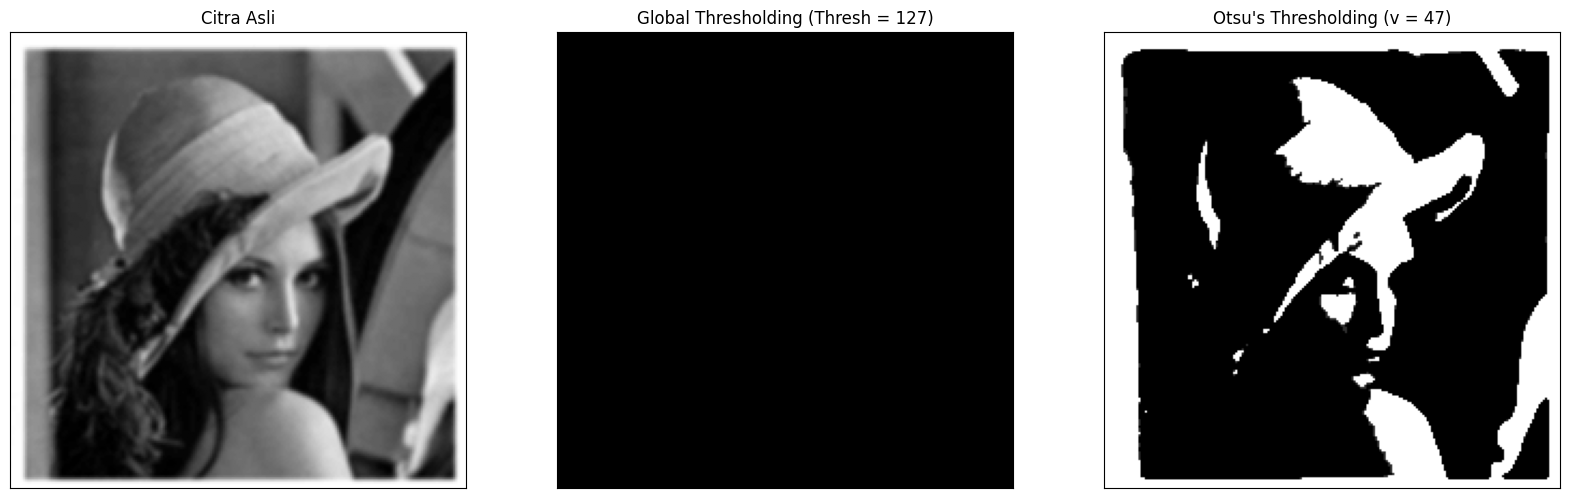

In [11]:
filename = 'lena_gs_lc2.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * ((mub - muf) ** 2)

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

B. Jawaban Pertanyaan Analisis No. 5

1. Penyebab Hitam Semua: Gambar lena_gs_lc2.jpg adalah citra berkontras rendah (low contrast) dengan rentang intensitas piksel sangat gelap
2. Penjelasan Histogram: Jika histogram ditampilkan, rentang grafik piksel hanya terkonsentrasi di daerah gelap (sebelah kiri, rentang $0-100$) dan tidak ada piksel yang melebihi angka $127$.
3. Nilai Ambang Batas Optimal: Angka ambang batas agar gambar masih terlihat adalah $T \approx 90 - 93$ (sesuai dengan nilai optimal yang didapatkan secara otomatis oleh algoritma Otsu Thresholding)

C. Pengujian dengan Image KTP

166


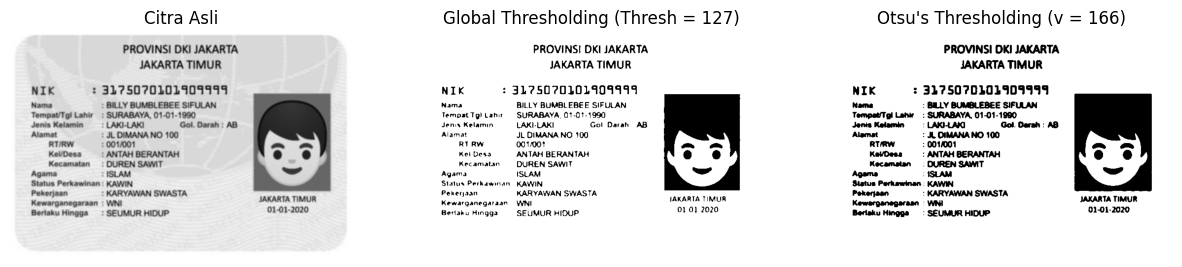

In [12]:
# Load Gambar KTP
img_ktp = cv.imread('/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg', 0)
if img_ktp is None:
    img_ktp = cv.imread('ktp_fulan.jpg', 0)

blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)
_, global_ktp = cv.threshold(blur_ktp, 127, 255, cv.THRESH_BINARY)
otsu_ktp_img, otsu_ktp_v = otsu(blur_ktp)

titles_ktp = ['Citra Asli', 'Global Thresholding (Thresh = 127)', f"Otsu's Thresholding (v = {otsu_ktp_v})"]
citra_ktp = [blur_ktp, global_ktp, otsu_ktp_img]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra_ktp[i], cmap='gray')
    plt.title(titles_ktp[i])
    plt.axis('off')
plt.show()

6. Segmentasi Berbasis Region

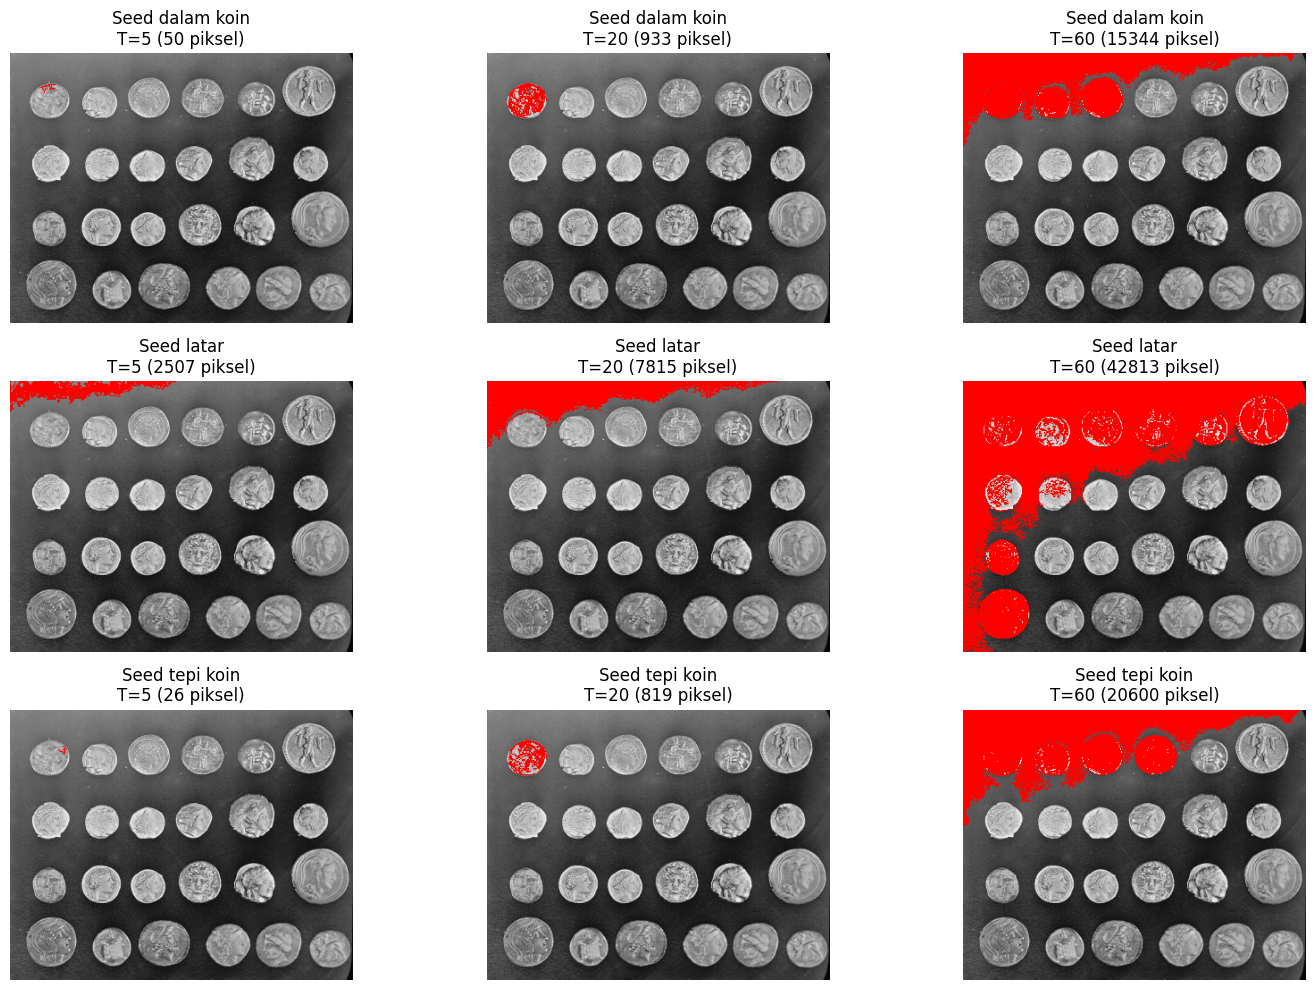

In [13]:
from skimage import data
from skimage.segmentation import flood

gray_coins = data.coins()

# Tentukan 3 posisi Seed: (baris, kolom)
# Seed 1: Dalam koin, Seed 2: Latar (background), Seed 3: Tepi koin
seeds = [(36, 43), (10, 10), (42, 62)]
seed_labels = ['Seed dalam koin', 'Seed latar', 'Seed tepi koin']
tolerances = [5, 20, 60]

plt.figure(figsize=(15, 10))
plot_idx = 1

for s_idx, seed in enumerate(seeds):
    for t_idx, T in enumerate(tolerances):
        # Jalankan Region Growing / Flood
        mask = flood(gray_coins, seed, tolerance=T)

        # Overlay warna merah pada area region
        img_result = cv.cvtColor(gray_coins, cv.COLOR_GRAY2RGB)
        img_result[mask] = [255, 0, 0] # Warna merah

        pix_count = np.sum(mask)
        plt.subplot(3, 3, plot_idx)
        plt.imshow(img_result)
        plt.title(f"{seed_labels[s_idx]}\nT={T} ({pix_count} piksel)")
        plt.axis('off')
        plot_idx += 1

plt.tight_layout()
plt.show()

7. egmentasi Warna pada ktp_fulan.jpg

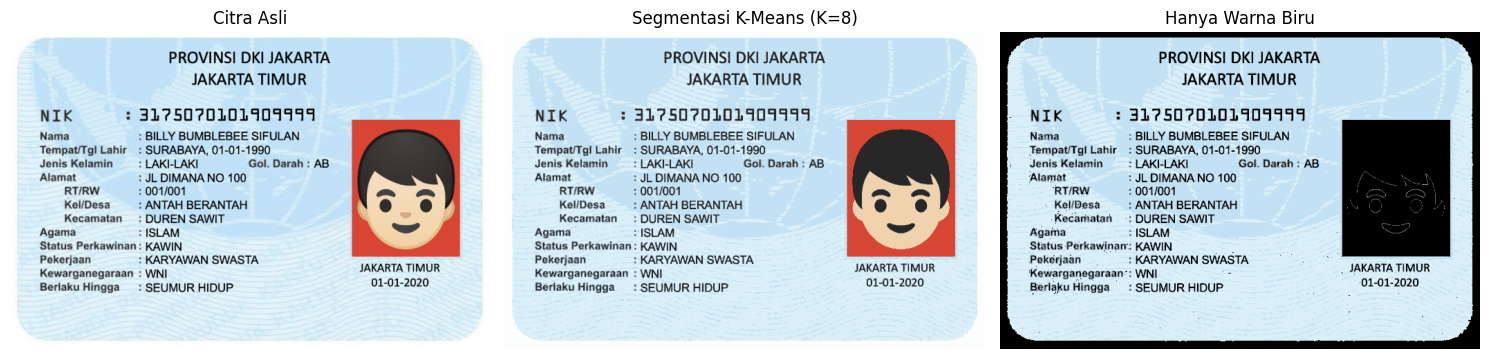

In [16]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Gambar KTP Berwarna
ktp_color = cv.imread('ktp_fulan.jpg')

# 2. Segmentasi K-Means Clustering (K=8)
data_pixels = ktp_color.reshape((-1, 3)).astype(np.float32)
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.2)
K = 8
_, labels, centers = cv.kmeans(data_pixels, K, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS)

centers = np.uint8(centers)
segmented_data = centers[labels.flatten()]
ktp_kmeans = segmented_data.reshape((ktp_color.shape))

# 3. Konversi ke HSV dan Isolasi Warna Biru Latar KTP
ktp_hsv = cv.cvtColor(ktp_kmeans, cv.COLOR_BGR2HSV)

# Rentang HSV OpenCV (H: 0-179, S: 0-255, V: 0-255)
# Disesuaikan agar mencakup seluruh spektrum biru muda latar KTP
lower_blue = np.array([75, 15, 30])
upper_blue = np.array([135, 255, 255])

mask_blue = cv.inRange(ktp_hsv, lower_blue, upper_blue)

# Isolasi hanya warna biru
only_blue = cv.bitwise_and(ktp_kmeans, ktp_kmeans, mask=mask_blue)

# 4. Visualisasi Hasil
titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images = [
    cv.cvtColor(ktp_color, cv.COLOR_BGR2RGB),
    cv.cvtColor(ktp_kmeans, cv.COLOR_BGR2RGB),
    cv.cvtColor(only_blue, cv.COLOR_BGR2RGB)
]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

**Tugas kelompok**

In [17]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


**Eksekusi Program OCR & Bounding Box**

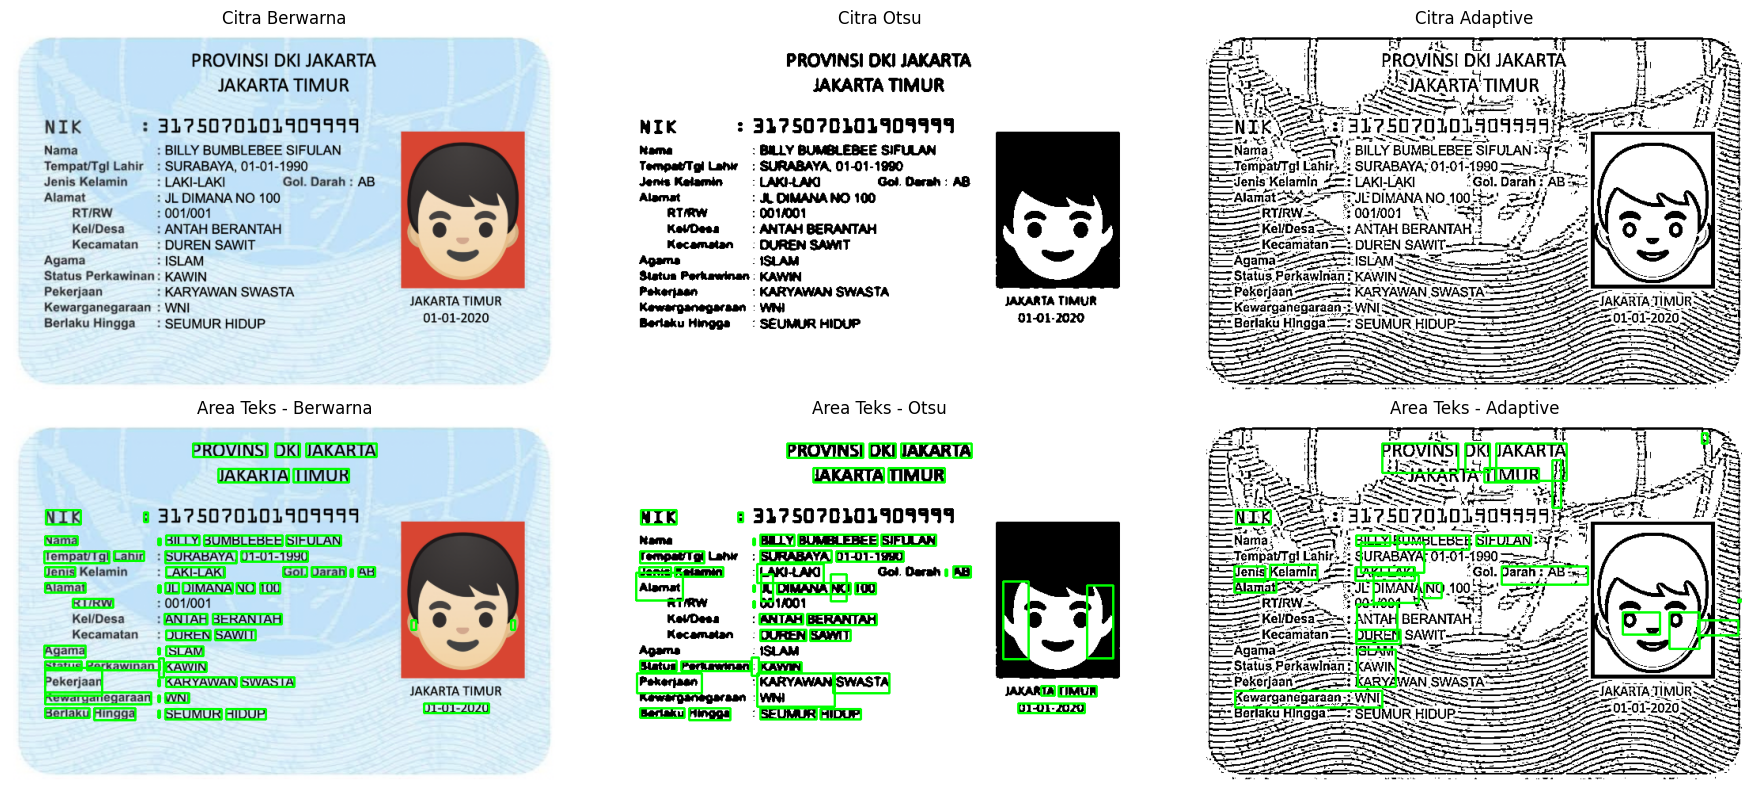

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31750?0101901411
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT t
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI SIata TOR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?507D101909919
kama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgi Lahu: SURABAYA, 01-01-1900
Jenis Kelamin LAKI-LAKI Gol. Daerah : AB
Alamat : JL DIMANA NO 100

RTRW : 0017001

KevDesa —: ANTAH BERANTAH d z )

Kecamatan: DUREN SAWIT
Status Perkawinan : KAWIN
Pekerjaan aan 8 KARYAWAN SWASTA TA TIMUR
Berlaku Hingga —: SEUMUR HIDUP 01-01-2020

========== ADAPTIVE ==========
sr (7 bg pr Ka it 3
“5 | PROVINSI DKI JAKARTA Eh 1
ea SSJAKARTA TIMUR | Ta!

Sm AN kt aah Bere IS
Pi Ae EA at Aha

In [18]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output

# 1. Load Citra KTP Berwarna
img_color = cv.imread('ktp_fulan.jpg')
img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)

# 2. Preprocessing Grayscale
gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

# 3. Segmentasi Otsu Thresholding
blur_otsu = cv.GaussianBlur(gray, (5, 5), 0)
_, img_otsu = cv.threshold(blur_otsu, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# 4. Segmentasi Adaptive Thresholding
img_adaptive = cv.adaptiveThreshold(
    gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2
)

# Kumpulan Citra untuk Diproses
images_dict = {
    'Berwarna': img_rgb.copy(),
    'Otsu': cv.cvtColor(img_otsu, cv.COLOR_GRAY2RGB),
    'Adaptive': cv.cvtColor(img_adaptive, cv.COLOR_GRAY2RGB)
}

# 5. Eksekusi OCR dan Bounding Box (Confidence > 60)
ocr_results = {}
confidence_scores = {}

custom_config = r'--psm 6 -l ind'  # Bahasa Indonesia dengan PSM 6 (single block text)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for idx, (title, img_input) in enumerate(images_dict.items()):
    # Baca Teks String
    text = pytesseract.image_to_string(img_input, config=custom_config)
    ocr_results[title] = text

    # Ambil Data Bounding Box & Confidence
    data = pytesseract.image_to_data(img_input, config=custom_config, output_type=Output.DICT)

    img_boxed = img_input.copy()
    conf_list = []

    n_boxes = len(data['text'])
    for i in range(n_boxes):
        conf = int(data['conf'][i])
        if conf > 60 and data['text'][i].strip() != '':
            conf_list.append(conf)
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(img_boxed, (x, y), (x + w, y + h), (0, 255, 0), 2)

    confidence_scores[title] = np.mean(conf_list) if conf_list else 0

    # Plot Gambar Asli/Hasil Thresholding
    axes[0, idx].imshow(img_input)
    axes[0, idx].set_title(f"Citra {title}")
    axes[0, idx].axis('off')

    # Plot Gambar dengan Bounding Box
    axes[1, idx].imshow(img_boxed)
    axes[1, idx].set_title(f"Area Teks - {title}")
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()

# Print Hasil Teks OCR
print("="*40)
for title, text in ocr_results.items():
    print(f"========== {title.upper()} ==========")
    print(text)
    print("="*40)